# Recurrent Neural Networks (RNN) on Structured Data
**SimpleRNN vs GRU on the Jena Climate time series (hourly temperature forecasting)**

Objective: build sliding windows over structured time-series data, train a baseline SimpleRNN and a GRU, and compare them, with a focus on how gating mitigates vanishing gradients.

## 1. Imports and setup

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

mpl.rcParams['figure.figsize'] = (10, 5)
mpl.rcParams['axes.grid'] = True

tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load the dataset

In [2]:
zip_path = tf.keras.utils.get_file(
    origin='https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip',
    fname='jena_climate_2009_2016.csv.zip',
    extract=True)
csv_path, _ = os.path.splitext(zip_path)
if os.path.isdir(csv_path):
    csv_path = os.path.join(csv_path, 'jena_climate_2009_2016.csv')

df = pd.read_csv(csv_path)
print(df.shape)
df.head()

13568290/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


## 3. Preprocessing (subsample, clean, feature engineering)

In [3]:
# Subsample: keep one record per hour (every 6th row of 10-min data)
df = df[5::6].copy()
date_time = pd.to_datetime(df.pop('Date Time'), format='%d.%m.%Y %H:%M:%S')

# Fix known bad values (-9999 sentinel) in wind columns
df.loc[df['wv (m/s)'] == -9999.0, 'wv (m/s)'] = 0.0
df.loc[df['max. wv (m/s)'] == -9999.0, 'max. wv (m/s)'] = 0.0

# Convert wind speed + direction into vector components
wv = df.pop('wv (m/s)')
max_wv = df.pop('max. wv (m/s)')
wd_rad = df.pop('wd (deg)') * np.pi / 180
df['Wx'] = wv * np.cos(wd_rad)
df['Wy'] = wv * np.sin(wd_rad)
df['max Wx'] = max_wv * np.cos(wd_rad)
df['max Wy'] = max_wv * np.sin(wd_rad)

# Time-of-day / time-of-year cyclical features
timestamp_s = date_time.map(pd.Timestamp.timestamp)
day = 24 * 60 * 60
year = 365.2425 * day
df['Day sin'] = np.sin(timestamp_s * (2 * np.pi / day))
df['Day cos'] = np.cos(timestamp_s * (2 * np.pi / day))
df['Year sin'] = np.sin(timestamp_s * (2 * np.pi / year))
df['Year cos'] = np.cos(timestamp_s * (2 * np.pi / year))

print(df.shape)
df.describe().T

(70091, 19)


,count,mean,std,min,25%,50%,75%,max
p (mbar),70091.0,989.212842,8.358886,913.600000,984.200000,9.895700e+02,994.720000,1015.290000
T (degC),70091.0,9.450482,8.423384,-22.760000,3.350000,9.410000e+00,15.480000,37.280000
Tpot (K),70091.0,283.493086,8.504424,250.850000,277.440000,2.834600e+02,289.530000,311.210000
Tdew (degC),70091.0,4.956471,6.730081,-24.800000,0.240000,5.210000e+00,10.080000,23.060000
rh (%),70091.0,76.009788,16.474920,13.880000,65.210000,7.930000e+01,89.400000,100.000000
VPmax (mbar),70091.0,13.576576,7.739883,0.970000,7.770000,1.182000e+01,17.610000,63.770000
VPact (mbar),70091.0,9.533968,4.183658,0.810000,6.220000,8.860000e+00,12.360000,28.250000
VPdef (mbar),70091.0,4.042536,4.898549,0.000000,0.870000,2.190000e+00,5.300000,46.010000
sh (g/kg),70091.0,6.022560,2.655812,0.510000,3.920000,5.590000e+00,7.800000,18.070000
H2OC (mmol/mol),70091.0,9.640437,4.234862,0.810000,6.290000,8.960000e+00,12.490000,28.740000


## 4. Train / validation / test split and normalization

In [4]:
n = len(df)
train_df = df[0:int(n * 0.7)]
val_df   = df[int(n * 0.7):int(n * 0.9)]
test_df  = df[int(n * 0.9):]

# Normalize using TRAIN statistics only (avoids data leakage)
train_mean = train_df.mean()
train_std  = train_df.std()

train_df = (train_df - train_mean) / train_std
val_df   = (val_df   - train_mean) / train_std
test_df  = (test_df  - train_mean) / train_std

print("Train:", train_df.shape, "Val:", val_df.shape, "Test:", test_df.shape)

Train: (49063, 19) Val: (14018, 19) Test: (7010, 19)


## 5. Sliding windows with `timeseries_dataset_from_array`
This is the modern Keras equivalent of the deprecated `TimeseriesGenerator`.

In [5]:
LOOKBACK = 24       # use past 24 hours
HORIZON = 1         # predict 1 hour ahead
BATCH = 64

target_col = 'T (degC)'
target_idx = list(train_df.columns).index(target_col)
num_features = train_df.shape[1]

def make_dataset(data, shuffle=False):
    arr = data.values.astype('float32')
    # Input windows: [t, t+LOOKBACK); target: temperature at t+LOOKBACK+HORIZON-1
    targets = arr[LOOKBACK + HORIZON - 1:, target_idx]
    ds = keras.utils.timeseries_dataset_from_array(
        data=arr[:-HORIZON],
        targets=targets,
        sequence_length=LOOKBACK,
        sequence_stride=1,
        shuffle=shuffle,
        batch_size=BATCH)
    return ds

train_ds = make_dataset(train_df, shuffle=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

for x, y in train_ds.take(1):
    print("Input batch:", x.shape, " Target batch:", y.shape)

Input batch: (64, 24, 19)  Target batch: (64,)


## 6. Baseline: naive "last value" predictor

In [6]:
def naive_baseline(ds):
    errs = []
    for x, y in ds:
        pred = x[:, -1, target_idx]
        errs.append(tf.abs(pred - y).numpy())
    return np.concatenate(errs).mean()

base_mae = naive_baseline(test_ds)
print(f"Naive baseline MAE (normalized): {base_mae:.4f}")
print(f"Naive baseline MAE (degC):       {base_mae * train_std[target_col]:.4f}")

Naive baseline MAE (normalized): 0.0854
Naive baseline MAE (degC):       0.7391


## 7. Model builders (SimpleRNN, GRU, optional LSTM)

In [7]:
def build_model(cell_type, units=32, layers_n=1):
    inp = keras.Input(shape=(LOOKBACK, num_features))
    x = inp
    for i in range(layers_n):
        return_seq = i < layers_n - 1
        if cell_type == 'SimpleRNN':
            x = layers.SimpleRNN(units, return_sequences=return_seq)(x)
        elif cell_type == 'GRU':
            x = layers.GRU(units, return_sequences=return_seq)(x)
        elif cell_type == 'LSTM':
            x = layers.LSTM(units, return_sequences=return_seq)(x)
    out = layers.Dense(1)(x)
    model = keras.Model(inp, out, name=f"{cell_type}_{layers_n}L")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='mse', metrics=['mae'])
    return model

build_model('SimpleRNN').summary()
build_model('GRU').summary()

Model: "SimpleRNN_1L"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 24, 19)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,697 (6.63 KB)

 Trainable params: 1,697 (6.63 KB)

 Non-trainable params: 0 (0.00 B)

Model: "GRU_1L"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 24, 19)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 32)             │         5,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Train both models

In [8]:
EPOCHS = 15
histories, train_times = {}, {}

for cell in ['SimpleRNN', 'GRU']:
    print(f"\n===== Training {cell} =====")
    model = build_model(cell, units=32, layers_n=1)
    cb = [keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)]
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds,
                  epochs=EPOCHS, callbacks=cb, verbose=1)
    train_times[cell] = time.time() - t0
    histories[cell] = (model, h)


===== Training SimpleRNN =====
Epoch 1/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - loss: 0.0375 - mae: 0.1285 - val_loss: 0.0112 - val_mae: 0.0776
Epoch 2/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0098 - mae: 0.0723 - val_loss: 0.0081 - val_mae: 0.0647
Epoch 3/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - loss: 0.0082 - mae: 0.0649 - val_loss: 0.0073 - val_mae: 0.0602
Epoch 4/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0076 - mae: 0.0622 - val_loss: 0.0072 - val_mae: 0.0594
Epoch 5/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0072 - mae: 0.0604 - val_loss: 0.0068 - val_mae: 0.0574
Epoch 6/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0071 - mae: 0.0596 - val_loss: 0.0066 - val_mae: 0.0566
Epoch 7/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0069 - mae: 0.0584 - val_loss: 0.0066 - val_mae: 0.0573
Epoch 8/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0068 - mae: 0.0581 - val_loss: 0.0065 - val_mae: 0.0568
Epoch 9/

## 9. Compare learning curves

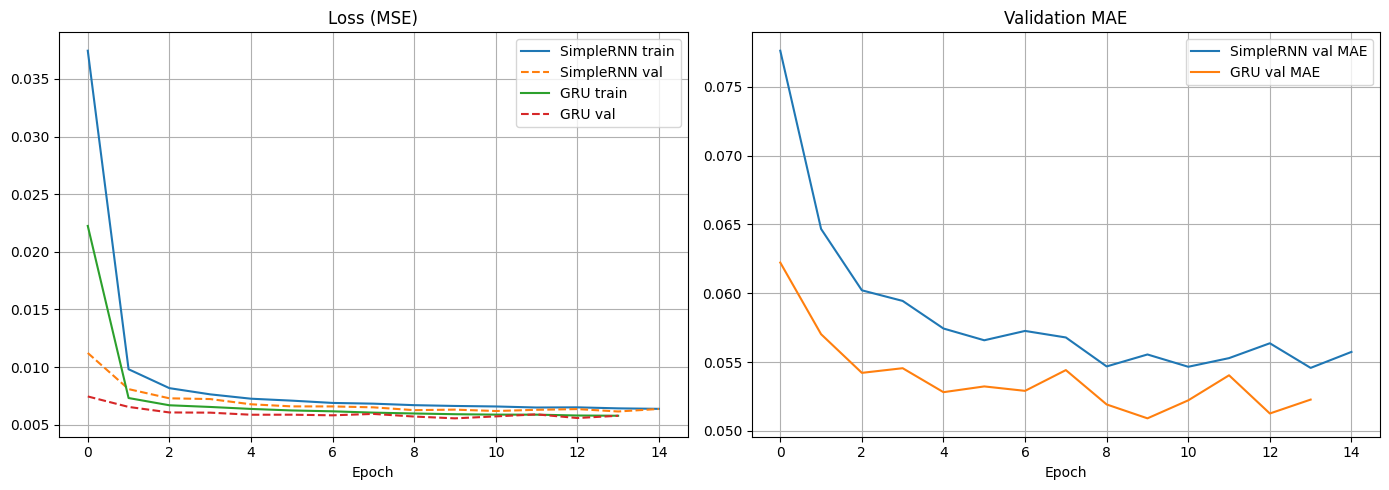

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for cell, (m, h) in histories.items():
    axes[0].plot(h.history['loss'], label=f'{cell} train')
    axes[0].plot(h.history['val_loss'], '--', label=f'{cell} val')
    axes[1].plot(h.history['val_mae'], label=f'{cell} val MAE')
axes[0].set_title('Loss (MSE)'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].set_title('Validation MAE'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout(); plt.show()

## 10. Test evaluation and results table

In [10]:
rows = []
for cell, (m, h) in histories.items():
    loss, mae = m.evaluate(test_ds, verbose=0)
    rows.append({
        'Model': cell,
        'Params': m.count_params(),
        'Test MSE': round(loss, 4),
        'Test MAE (norm)': round(mae, 4),
        'Test MAE (degC)': round(mae * train_std[target_col], 3),
        'Train time (s)': round(train_times[cell], 1),
        'Epochs run': len(h.history['loss'])
    })
rows.append({'Model': 'Naive baseline', 'Params': 0, 'Test MSE': np.nan,
             'Test MAE (norm)': round(base_mae, 4),
             'Test MAE (degC)': round(base_mae * train_std[target_col], 3),
             'Train time (s)': 0, 'Epochs run': 0})
results = pd.DataFrame(rows)
results

,Model,Params,Test MSE,Test MAE (norm),Test MAE (degC),Train time (s),Epochs run
0,SimpleRNN,1697,0.0061,0.0557,0.482,180.7,15
1,GRU,5121,0.0056,0.0520,0.450,176.8,14
2,Naive baseline,0,NaN,0.0854,0.739,0.0,0


## 11. Prediction plot (actual vs predicted)

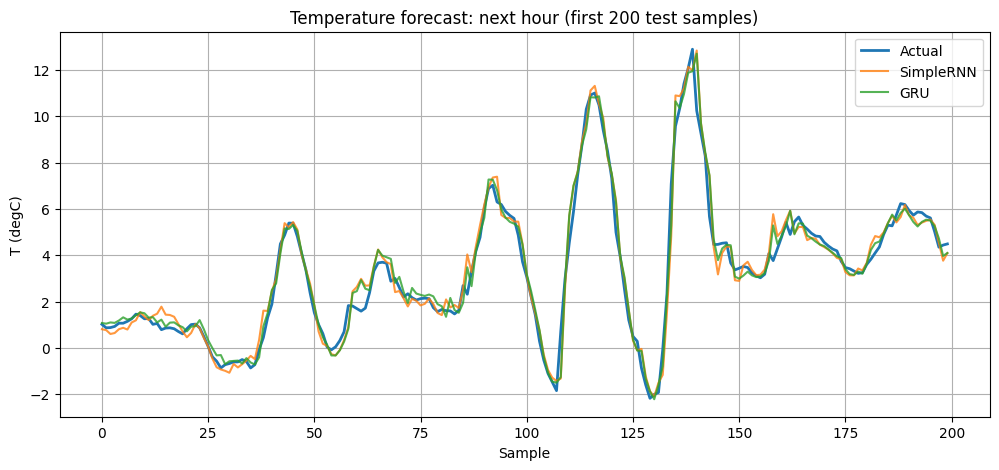

In [11]:
x_test, y_test = next(iter(test_ds.unbatch().batch(200)))
plt.figure(figsize=(12, 5))
plt.plot(y_test.numpy() * train_std[target_col] + train_mean[target_col],
         label='Actual', linewidth=2)
for cell, (m, h) in histories.items():
    p = m.predict(x_test, verbose=0).flatten()
    plt.plot(p * train_std[target_col] + train_mean[target_col], label=cell, alpha=0.8)
plt.title('Temperature forecast: next hour (first 200 test samples)')
plt.xlabel('Sample'); plt.ylabel('T (degC)'); plt.legend(); plt.show()

## 12. Vanishing-gradient experiment
A longer lookback (120 steps) forces gradients to flow across many time steps. We then measure gradient magnitude per input time step.


=== Long-lookback training: SimpleRNN ===
Epoch 1/5
765/765 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - loss: 0.0674 - mae: 0.1530 - val_loss: 0.0124 - val_mae: 0.0830
Epoch 2/5
765/765 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0105 - mae: 0.0750 - val_loss: 0.0086 - val_mae: 0.0672
Epoch 3/5
765/765 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0083 - mae: 0.0658 - val_loss: 0.0074 - val_mae: 0.0609
Epoch 4/5
765/765 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 0.0076 - mae: 0.0623 - val_loss: 0.0068 - val_mae: 0.0588
Epoch 5/5
765/765 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - loss: 0.0072 - mae: 0.0603 - val_loss: 0.0074 - val_mae: 0.0615

=== Long-lookback training: GRU ===
Epoch 1/5
765/765 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - loss: 0.0434 - mae: 0.1141 - val_loss: 0.0085 - val_mae: 0.0674
Epoch 2/5
765/765 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 0.0077 - mae: 0.0631 - val_loss: 0.0067 - val_mae: 0.0585
Epoch 3/5
765/765 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - loss: 0.0069 - mae: 0.0588 - val

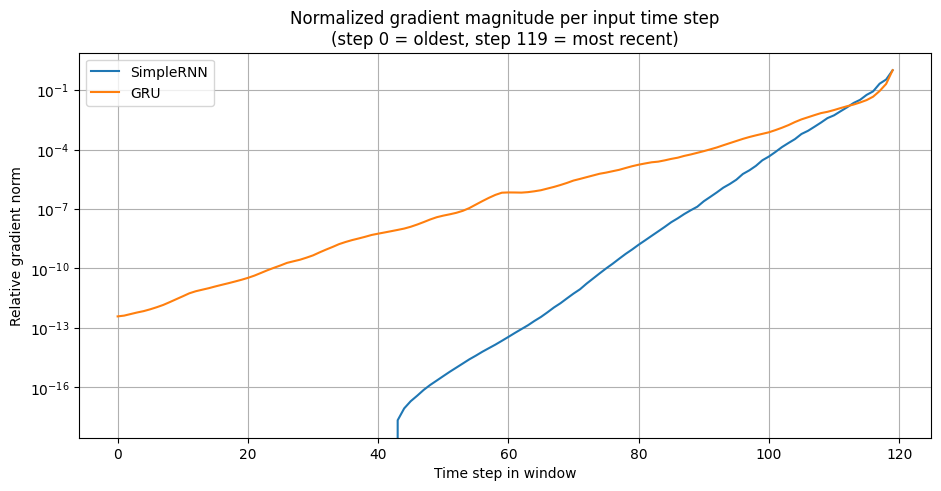

In [12]:
LONG_LOOKBACK = 120

def make_long_ds(data, shuffle=False):
    arr = data.values.astype('float32')
    targets = arr[LONG_LOOKBACK:, target_idx]
    return keras.utils.timeseries_dataset_from_array(
        arr[:-1], targets, sequence_length=LONG_LOOKBACK,
        batch_size=BATCH, shuffle=shuffle)

long_train = make_long_ds(train_df, True)
long_val   = make_long_ds(val_df)

def build_long(cell_type, units=32):
    inp = keras.Input(shape=(LONG_LOOKBACK, num_features))
    L = layers.SimpleRNN if cell_type == 'SimpleRNN' else layers.GRU
    x = L(units)(inp)
    out = layers.Dense(1)(x)
    m = keras.Model(inp, out)
    m.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return m

def gradient_per_timestep(model, x_batch, y_batch):
    """Gradient norm of the loss w.r.t. the input at each time step."""
    x = tf.convert_to_tensor(x_batch)
    with tf.GradientTape() as tape:
        tape.watch(x)
        pred = model(x, training=True)
        loss = tf.reduce_mean(tf.square(pred - tf.reshape(y_batch, pred.shape)))
    g = tape.gradient(loss, x)                      # (batch, time, features)
    return tf.reduce_mean(tf.norm(g, axis=-1), axis=0).numpy()  # (time,)

long_models = {}
for cell in ['SimpleRNN', 'GRU']:
    print(f"\n=== Long-lookback training: {cell} ===")
    m = build_long(cell)
    m.fit(long_train, validation_data=long_val, epochs=5, verbose=1)
    long_models[cell] = m

xb, yb = next(iter(long_val))
plt.figure(figsize=(11, 5))
for cell, m in long_models.items():
    g = gradient_per_timestep(m, xb, yb)
    plt.plot(g / (g.max() + 1e-12), label=cell)
plt.title('Normalized gradient magnitude per input time step\n(step 0 = oldest, step 119 = most recent)')
plt.xlabel('Time step in window'); plt.ylabel('Relative gradient norm')
plt.yscale('log'); plt.legend(); plt.show()

## 13. Effect of lookback length on both models

lookback=  6 SimpleRNN MAE=0.510 degC
lookback=  6 GRU       MAE=0.483 degC
lookback= 24 SimpleRNN MAE=0.531 degC
lookback= 24 GRU       MAE=0.477 degC
lookback= 72 SimpleRNN MAE=0.515 degC
lookback= 72 GRU       MAE=0.494 degC
lookback=120 SimpleRNN MAE=0.496 degC
lookback=120 GRU       MAE=0.471 degC


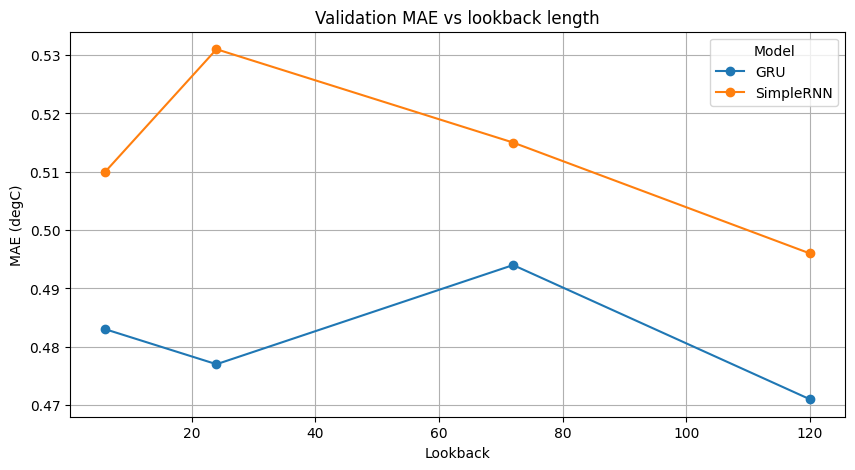

Model,GRU,SimpleRNN
Lookback,,
6,0.483,0.510
24,0.477,0.531
72,0.494,0.515
120,0.471,0.496


In [13]:
lookbacks = [6, 24, 72, 120]
summary = []
for lb in lookbacks:
    arr_train = train_df.values.astype('float32')
    arr_val = val_df.values.astype('float32')
    tr = keras.utils.timeseries_dataset_from_array(
        arr_train[:-1], arr_train[lb:, target_idx], lb, batch_size=BATCH, shuffle=True)
    va = keras.utils.timeseries_dataset_from_array(
        arr_val[:-1], arr_val[lb:, target_idx], lb, batch_size=BATCH)
    for cell in ['SimpleRNN', 'GRU']:
        inp = keras.Input(shape=(lb, num_features))
        L = layers.SimpleRNN if cell == 'SimpleRNN' else layers.GRU
        out = layers.Dense(1)(L(32)(inp))
        m = keras.Model(inp, out)
        m.compile('adam', 'mse', metrics=['mae'])
        m.fit(tr, validation_data=va, epochs=4, verbose=0)
        _, mae = m.evaluate(va, verbose=0)
        summary.append({'Lookback': lb, 'Model': cell,
                        'Val MAE (degC)': round(mae * train_std[target_col], 3)})
        print(f"lookback={lb:3d} {cell:9s} MAE={mae * train_std[target_col]:.3f} degC")

pivot = pd.DataFrame(summary).pivot(index='Lookback', columns='Model', values='Val MAE (degC)')
pivot.plot(marker='o', title='Validation MAE vs lookback length')
plt.ylabel('MAE (degC)'); plt.show()
pivot

## 14. Sequence padding and masking demo
The Jena data is regular, so padding isn't needed for training. This shows how `pad_sequences` and `Masking` handle variable-length histories.

In [15]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Simulate variable-length history (e.g., a station with a short record)
sample = train_df.values[:100].astype('float32')
variable_seqs = [sample[:10], sample[:18], sample[:24]]

padded = pad_sequences(variable_seqs, maxlen=LOOKBACK, dtype='float32',
                       padding='pre', truncating='pre', value=0.0)
print("Padded shape:", padded.shape)   # (3, 24, num_features)

# Masking tells the RNN to ignore the padded zeros
inp = keras.Input(shape=(LOOKBACK, num_features))
x = layers.Masking(mask_value=0.0)(inp)
# Disable cuDNN to allow pre-padded masks
x = layers.GRU(32, use_cudnn=False)(x)
out = layers.Dense(1)(x)
masked_model = keras.Model(inp, out)
print(masked_model.predict(padded, verbose=0).shape)

Padded shape: (3, 24, 19)


(3, 1)


## 15. Observations (fill in after running)
- **SimpleRNN vs GRU on short windows:**
- **Gradient plot (Section 12):** SimpleRNN gradients typically decay sharply toward older time steps; GRU update/reset gates keep gradient flow more even.
- **Lookback sweep (Section 13):**
- **Training time / parameters:** GRU has roughly 3x the recurrent parameters of SimpleRNN at the same width.